# Sensitivitas kalibrasi 30/60/90 hari — median dan Ridge

Kalibrasi lama adalah warmup statistik untuk prefix median, bukan kalibrasi sensor. Data awal tetap asli, imputasi histori baru dimulai setelah warmup, sampel model menunggu buffer48slot. Median train diperbarui tiap30hari secara kausal dan dibekukan untuk evaluasi. Uji mengubah warmup dan komposisi train, bukan imputasi saja. Tidak memakai deep learning atau test akhir.

Train median mandiri, tidak memakai irisan P1/KNN lama. Semua empat fold evaluasi tahap6 dipertahankan. Penjelasan fungsi warmup ditetapkan sebelum eksperimen dijalankan.

In [1]:
from pathlib import Path
import sys
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'scripts'))
from calibration_sensitivity import Sensitivity
from IPython.display import display,Markdown,Image
import pandas as pd
s=Sensitivity().prepare()
print('SHA256 konfigurasi pra-fit:',s.config_hash)
display(pd.DataFrame(s.cfg['folds']))


Konfigurasi dikunci sebelum12fit: 594d344745fda9723d5b00b106a83977fedd6aa11a5636155ce1dc51025abfa8
SHA256 konfigurasi pra-fit: 594d344745fda9723d5b00b106a83977fedd6aa11a5636155ce1dc51025abfa8


,Fold,Train mulai,Train akhir,Validasi mulai,Validasi akhir,Validasi akhir eksklusif,Slot train,Slot validasi,Durasi validasi jam,Index awal validasi,Index akhir validasi eksklusif
0,Fold_01,2025-01-01 00:00:00,2025-04-30 23:30:00,2025-05-01 00:00:00,2025-08-12 13:30:00,2025-08-12 14:00:00,5760,4972,2486.0,5760,10732
1,Fold_02,2025-01-01 00:00:00,2025-08-12 13:30:00,2025-08-12 14:00:00,2025-11-24 03:00:00,2025-11-24 03:30:00,10732,4971,2485.5,10732,15703
2,Fold_03,2025-01-01 00:00:00,2025-11-24 03:00:00,2025-11-24 03:30:00,2026-03-07 16:30:00,2026-03-07 17:00:00,15703,4971,2485.5,15703,20674
3,Fold_04,2025-01-01 00:00:00,2026-03-07 16:30:00,2026-03-07 17:00:00,2026-06-19 06:00:00,2026-06-19 06:30:00,20674,4971,2485.5,20674,25645


## Persiapan seluruh konfigurasi sebelum Ridge

Median menggunakan rawprefix sebelum query; bukan median seluruh train untuk histori awal. Scaler Ridge hanya fit pada traineligible fold/durasi. Target asli, buffer48slot, purge batas, 34fitur tanpa CurahHujan tetap. Laporkan calon sampel, distribusi dan prefix tanpa median sebelum12fit. Jangan memaksakan irisan train antar-durasi: perubahan cohort adalah objek sensitivitas.

In [2]:
s.prepare_all()
display(pd.DataFrame([c.gate for c in s.cases]))
display(pd.DataFrame([c.flow for c in s.cases]))
display(pd.DataFrame([c.dist for c in s.cases]))
display(pd.DataFrame(s.legacy))
display(pd.DataFrame(s.input_checks))
print('Ridge fit sebelum semua gate:',s.fit_count)


   Fold  Kalibrasi hari         Origin awal        Origin akhir         Target awal        Target akhir  Minimum      P1   P25  Median   P75     P99  Maksimum     N      Mean        SD  SO2 lebih2.14
Fold_01              30 2025-02-13 18:30:00 2025-04-30 23:00:00 2025-02-13 19:00:00 2025-04-30 23:30:00     1.24  1.3300 44.42   45.24 45.82 77.3500     80.71  3539 38.468346 19.885072           2832
Fold_01              60 2025-03-03 00:00:00 2025-04-30 23:00:00 2025-03-03 00:30:00 2025-04-30 23:30:00    43.31 43.9800 45.00   45.43 45.89 76.8967     80.71  2712 46.512327  5.740881           2712
Fold_01              90 2025-04-02 00:00:00 2025-04-30 23:00:00 2025-04-02 00:30:00 2025-04-30 23:30:00    43.53 44.0284 45.00   45.40 45.82 46.9300     47.43  1385 45.403986  0.624118           1385
Fold_02              30 2025-02-13 18:30:00 2025-08-12 13:00:00 2025-02-13 19:00:00 2025-08-12 13:30:00     1.07  1.3000  1.58   44.91 45.61 75.9260     80.71  8429 29.831345 22.337377           5288


,Fold,Kalibrasi hari,Ridge fit sebelum gate,Train N,Fitur,Prefix tanpa median,Lulus
0,Fold_01,30,0,3539,34,0,True
1,Fold_01,60,0,2712,34,0,True
2,Fold_01,90,0,1385,34,0,True
3,Fold_02,30,0,8429,34,0,True
4,Fold_02,60,0,7602,34,0,True
5,Fold_02,90,0,6275,34,0,True
6,Fold_03,30,0,13398,34,0,True
7,Fold_03,60,0,12571,34,0,True
8,Fold_03,90,0,11244,34,0,True
9,Fold_04,30,0,18367,34,0,True


,Fold,Kalibrasi hari,Slot origin train,Warmup dikeluarkan,Buffer lag48,Purge batas,Kandidat setelah warmup buffer purge,Target asli kandidat,Target kosong kandidat,Fitur nonfinite kandidat target teramati,Train dipakai,Jumlah tersisih
0,Fold_01,30,5760,1440,48,1,4271,3539,732,0,3539,2221
1,Fold_01,60,5760,2880,48,1,2831,2712,119,0,2712,3048
2,Fold_01,90,5760,4320,48,1,1391,1385,6,0,1385,4375
3,Fold_02,30,10732,1440,48,1,9243,8429,814,0,8429,2303
4,Fold_02,60,10732,2880,48,1,7803,7602,201,0,7602,3130
5,Fold_02,90,10732,4320,48,1,6363,6275,88,0,6275,4457
6,Fold_03,30,15703,1440,48,1,14214,13398,816,0,13398,2305
7,Fold_03,60,15703,2880,48,1,12774,12571,203,0,12571,3132
8,Fold_03,90,15703,4320,48,1,11334,11244,90,0,11244,4459
9,Fold_04,30,20674,1440,48,1,19185,18367,818,0,18367,2307


,Fold,Kalibrasi hari,Origin awal,Origin akhir,Target awal,Target akhir,Minimum,P1,P25,Median,P75,P99,Maksimum,N,Mean,SD,SO2 lebih2.14
0,Fold_01,30,2025-02-13 18:30:00,2025-04-30 23:00:00,2025-02-13 19:00:00,2025-04-30 23:30:00,1.24,1.3300,44.42,45.24,45.82,77.3500,80.71,3539,38.468346,19.885072,2832
1,Fold_01,60,2025-03-03 00:00:00,2025-04-30 23:00:00,2025-03-03 00:30:00,2025-04-30 23:30:00,43.31,43.9800,45.00,45.43,45.89,76.8967,80.71,2712,46.512327,5.740881,2712
2,Fold_01,90,2025-04-02 00:00:00,2025-04-30 23:00:00,2025-04-02 00:30:00,2025-04-30 23:30:00,43.53,44.0284,45.00,45.40,45.82,46.9300,47.43,1385,45.403986,0.624118,1385
3,Fold_02,30,2025-02-13 18:30:00,2025-08-12 13:00:00,2025-02-13 19:00:00,2025-08-12 13:30:00,1.07,1.3000,1.58,44.91,45.61,75.9260,80.71,8429,29.831345,22.337377,5288
4,Fold_02,60,2025-03-03 00:00:00,2025-08-12 13:00:00,2025-03-03 00:30:00,2025-08-12 13:30:00,1.07,1.3000,1.65,45.02,45.64,74.4798,80.71,7602,31.761426,21.018329,5168
5,Fold_02,90,2025-04-02 00:00:00,2025-08-12 13:00:00,2025-04-02 00:30:00,2025-08-12 13:30:00,1.07,1.2900,1.60,44.85,45.54,46.7900,47.81,6275,28.397363,21.372070,3841
6,Fold_03,30,2025-02-13 18:30:00,2025-11-24 02:30:00,2025-02-13 19:00:00,2025-11-24 03:00:00,1.04,1.2400,1.52,1.66,45.20,75.0100,80.71,13398,19.346516,22.369445,5288
7,Fold_03,60,2025-03-03 00:00:00,2025-11-24 02:30:00,2025-03-03 00:30:00,2025-11-24 03:00:00,1.04,1.2370,1.54,1.68,45.23,47.0930,80.71,12571,19.823926,22.026677,5168
8,Fold_03,90,2025-04-02 00:00:00,2025-11-24 02:30:00,2025-04-02 00:30:00,2025-11-24 03:00:00,1.04,1.2243,1.53,1.64,45.02,46.6200,47.81,11244,16.537679,20.797468,3841
9,Fold_04,30,2025-02-13 18:30:00,2026-03-07 16:00:00,2025-02-13 19:00:00,2026-03-07 16:30:00,1.04,1.2300,1.51,1.61,44.71,73.7668,80.71,18367,14.535297,20.674395,5288


,Fold,C90 fitur identik P0 tahap6,Train P0 tahap6 irisan3,C90 median mandiri,Tambahan karena tidak memakai irisan P1 KNN,Minimum,P1,P25,Median,P75,P99,Maksimum,N,Mean,SD,SO2 lebih2.14
0,Fold_01,True,1379,1385,6,44.55,44.5540,44.7225,45.20,45.775,46.2610,46.28,6,45.293333,0.697357,6
1,Fold_02,True,6190,6275,85,1.16,1.2608,1.6900,44.87,45.480,46.5792,46.68,85,29.877765,21.014197,55
2,Fold_03,True,11154,11244,90,1.16,1.2668,1.6900,44.68,45.430,46.5732,46.68,90,28.303667,21.433240,55
3,Fold_04,True,16086,16213,127,1.16,1.2504,1.5650,1.73,45.195,46.4872,46.68,127,20.514094,21.754448,55


,Fold,Kalibrasi hari,C90 fitur vs tahap6 cocok,Fitur evaluasi belum scaling identik antar kalibrasi,Origin evaluasi,Selisih maksimum finite
0,Fold_01,30,True,True,4972,0.0
1,Fold_01,60,True,True,4972,0.0
2,Fold_01,90,True,True,4972,0.0
3,Fold_02,30,True,True,4971,0.0
4,Fold_02,60,True,True,4971,0.0
5,Fold_02,90,True,True,4971,0.0
6,Fold_03,30,True,True,4971,0.0
7,Fold_03,60,True,True,4971,0.0
8,Fold_03,90,True,True,4971,0.0
9,Fold_04,30,True,True,4971,0.0


## Fit12Ridge dan evaluasi pada target asli

Satu Ridge per fold/durasi, tanpa targetscaling. Evaluasi bersama3durasi+persistence pada tanggal yang sama. Cakupan mandiri dan semua target asli dilaporkan. Persistence memakai pengamatan asli terakhir pada/sebelum origin. Tidak mengisi target atau memilih durasi berdasarkan skor rerata saja.

,Fold,Konfigurasi,Domain,N,Denominator target asli,Cakupan persen,MAE,RMSE,Bias,Prediksi negatif,SHA256 timestamp
0,Fold_01,C30_median,mandiri,4890,4890,100.0,17.245739,40.229392,-11.924223,1317,2a6708180361da393dc963ce8cc2366dd4837d308b8a5b...
1,Fold_01,C30_median,bersama,4890,4890,100.0,17.245739,40.229392,-11.924223,1317,2a6708180361da393dc963ce8cc2366dd4837d308b8a5b...
2,Fold_01,C60_median,mandiri,4890,4890,100.0,15.796595,23.826218,15.247600,91,2a6708180361da393dc963ce8cc2366dd4837d308b8a5b...
3,Fold_01,C60_median,bersama,4890,4890,100.0,15.796595,23.826218,15.247600,91,2a6708180361da393dc963ce8cc2366dd4837d308b8a5b...
4,Fold_01,C90_median,mandiri,4890,4890,100.0,16.655304,24.730388,16.110781,103,2a6708180361da393dc963ce8cc2366dd4837d308b8a5b...
5,Fold_01,C90_median,bersama,4890,4890,100.0,16.655304,24.730388,16.110781,103,2a6708180361da393dc963ce8cc2366dd4837d308b8a5b...
6,Fold_01,Persistence,mandiri,4890,4890,100.0,0.430562,0.885256,0.009049,0,2a6708180361da393dc963ce8cc2366dd4837d308b8a5b...
7,Fold_01,Persistence,bersama,4890,4890,100.0,0.430562,0.885256,0.009049,0,2a6708180361da393dc963ce8cc2366dd4837d308b8a5b...
8,Fold_02,C30_median,mandiri,4969,4969,100.0,0.216147,0.608248,-0.110496,0,1d688ac4f4a18f27cc83901b88374c4d81006e9beb785d...
9,Fold_02,C30_median,bersama,4969,4969,100.0,0.216147,0.608248,-0.110496,0,1d688ac4f4a18f27cc83901b88374c4d81006e9beb785d...


,Fold,Konfigurasi,Domain,N,Denominator target asli,Cakupan persen,MAE,RMSE,Bias,Prediksi negatif,SHA256 timestamp
0,Gabungan_OOF,C30_median,mandiri,19797,19797,100.0,4.370998,19.996605,-2.982118,1321,1663821d30ee4523fd8c636c175f3570cf6976594a170f...
1,Gabungan_OOF,C30_median,bersama,19797,19797,100.0,4.370998,19.996605,-2.982118,1321,1663821d30ee4523fd8c636c175f3570cf6976594a170f...
2,Gabungan_OOF,C60_median,mandiri,19797,19797,100.0,4.036792,11.846249,3.708798,98,1663821d30ee4523fd8c636c175f3570cf6976594a170f...
3,Gabungan_OOF,C60_median,bersama,19797,19797,100.0,4.036792,11.846249,3.708798,98,1663821d30ee4523fd8c636c175f3570cf6976594a170f...
4,Gabungan_OOF,C90_median,mandiri,19797,19797,100.0,4.218115,12.293788,3.947609,116,1663821d30ee4523fd8c636c175f3570cf6976594a170f...
5,Gabungan_OOF,C90_median,bersama,19797,19797,100.0,4.218115,12.293788,3.947609,116,1663821d30ee4523fd8c636c175f3570cf6976594a170f...
6,Gabungan_OOF,Persistence,mandiri,19797,19797,100.0,0.206335,0.464340,0.002240,0,1663821d30ee4523fd8c636c175f3570cf6976594a170f...
7,Gabungan_OOF,Persistence,bersama,19797,19797,100.0,0.206335,0.464340,0.002240,0,1663821d30ee4523fd8c636c175f3570cf6976594a170f...


,Konfigurasi,Domain,Fold N,MAE mean fold,MAE SD fold,MAE min fold,MAE max fold,RMSE mean fold,RMSE SD fold,RMSE min fold,RMSE max fold,Bias mean fold,Bias SD fold,Bias min fold,Bias max fold,Cakupan persen mean fold,Cakupan persen SD fold,Cakupan persen min fold,Cakupan persen max fold,N mean fold,N SD fold,N min fold,N max fold
0,C30_median,mandiri,4,4.422170,8.549187,0.103623,17.245739,10.292793,19.958820,0.154645,40.229392,-3.017659,5.937871,-11.924223,-0.012214,100.0,0.0,100.0,100.0,4949.25,39.5,4890.0,4969.0
1,C30_median,bersama,4,4.422170,8.549187,0.103623,17.245739,10.292793,19.958820,0.154645,40.229392,-3.017659,5.937871,-11.924223,-0.012214,100.0,0.0,100.0,100.0,4949.25,39.5,4890.0,4969.0
2,C60_median,mandiri,4,4.083533,7.809181,0.108887,15.796595,6.196556,11.754993,0.160042,23.826218,3.754660,7.662272,-0.173761,15.247600,100.0,0.0,100.0,100.0,4949.25,39.5,4890.0,4969.0
3,C60_median,bersama,4,4.083533,7.809181,0.108887,15.796595,6.196556,11.754993,0.160042,23.826218,3.754660,7.662272,-0.173761,15.247600,100.0,0.0,100.0,100.0,4949.25,39.5,4890.0,4969.0
4,C90_median,mandiri,4,4.267549,8.258569,0.106864,16.655304,6.405983,12.216424,0.237953,24.730388,3.995954,8.076591,-0.077911,16.110781,100.0,0.0,100.0,100.0,4949.25,39.5,4890.0,4969.0
5,C90_median,bersama,4,4.267549,8.258569,0.106864,16.655304,6.405983,12.216424,0.237953,24.730388,3.995954,8.076591,-0.077911,16.110781,100.0,0.0,100.0,100.0,4949.25,39.5,4890.0,4969.0
6,Persistence,mandiri,4,0.207226,0.149373,0.115935,0.430562,0.349112,0.357753,0.149092,0.885256,0.002267,0.004521,-0.000020,0.009049,100.0,0.0,100.0,100.0,4949.25,39.5,4890.0,4969.0
7,Persistence,bersama,4,0.207226,0.149373,0.115935,0.430562,0.349112,0.357753,0.149092,0.885256,0.002267,0.004521,-0.000020,0.009049,100.0,0.0,100.0,100.0,4949.25,39.5,4890.0,4969.0


,Fold,Konfigurasi,N sama,Delta MAE vs persistence,Delta RMSE vs persistence,Delta Bias vs persistence
0,Fold_01,C30_median,4890,16.815177,39.344136,-11.933272
1,Fold_01,C60_median,4890,15.366033,22.940963,15.238551
2,Fold_01,C90_median,4890,16.224742,23.845132,16.101732
3,Fold_02,C30_median,4969,0.073193,0.424566,-0.110476
4,Fold_02,C60_median,4969,0.157306,0.433692,-0.173740
5,Fold_02,C90_median,4969,0.040734,0.198406,-0.077891
6,Fold_03,C30_median,4969,-0.016282,0.000468,-0.023719
7,Fold_03,C60_median,4969,-0.011062,0.004170,-0.035245
8,Fold_03,C90_median,4969,-0.015115,0.095085,-0.026490
9,Fold_04,C30_median,4969,-0.012312,0.005553,-0.012238


,File,SHA256 sebelum,SHA256 sesudah,Identik
0,outputs\audit_kualitas_data.xlsx,7e1a6059f5660aa50deec62ae7d498361fadafa0b4e093...,7e1a6059f5660aa50deec62ae7d498361fadafa0b4e093...,True
1,outputs\audit_kualitas_tables.json,89bf7a39781e9ea3368a8c7a4731cf7c8c36523eb117a2...,89bf7a39781e9ea3368a8c7a4731cf7c8c36523eb117a2...,True
2,outputs\audit_struktur_data.json,75de5795076e22bb46784e70b238b2778a7e77f75953e9...,75de5795076e22bb46784e70b238b2778a7e77f75953e9...,True
3,outputs\backtesting_preprocessing.xlsx,26a333c035b1ac9156d1d1c51efdd6c5958c9bcaf8785f...,26a333c035b1ac9156d1d1c51efdd6c5958c9bcaf8785f...,True
4,outputs\diagnosis_fold1.md,a882195c50534a8f37b73441cf4071ee6f429675e9244c...,a882195c50534a8f37b73441cf4071ee6f429675e9244c...,True
...,...,...,...,...
362,scripts\write_stage5_trace_report.py,374b46acc2fc6c2084fa0b998fefa5078851918d917825...,374b46acc2fc6c2084fa0b998fefa5078851918d917825...,True
363,requirements.txt,f141bf5fb044dad4db759010798311714edb9c2e3aac15...,f141bf5fb044dad4db759010798311714edb9c2e3aac15...,True
364,requirements-lstm-lock.txt,12f0a2454cd55579c7eb7c8109bc26cffc0cc29b8100b4...,12f0a2454cd55579c7eb7c8109bc26cffc0cc29b8100b4...,True
365,.venv\pyvenv.cfg,8414c7b1b615379c5aa4c3f6690c54e84a4557fd2244ef...,8414c7b1b615379c5aa4c3f6690c54e84a4557fd2244ef...,True


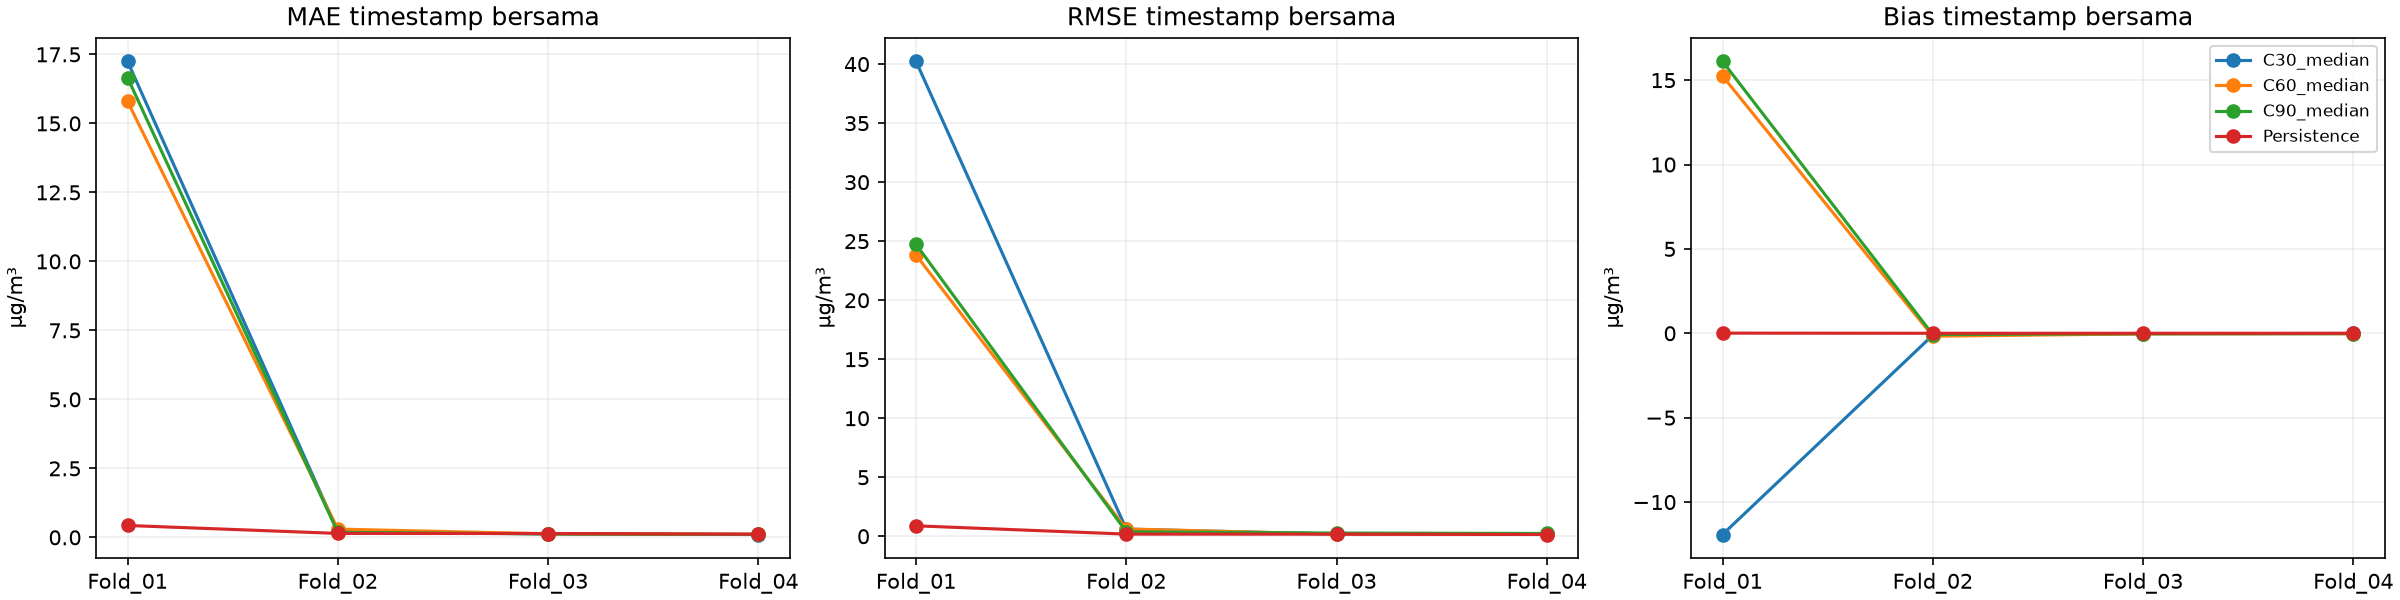

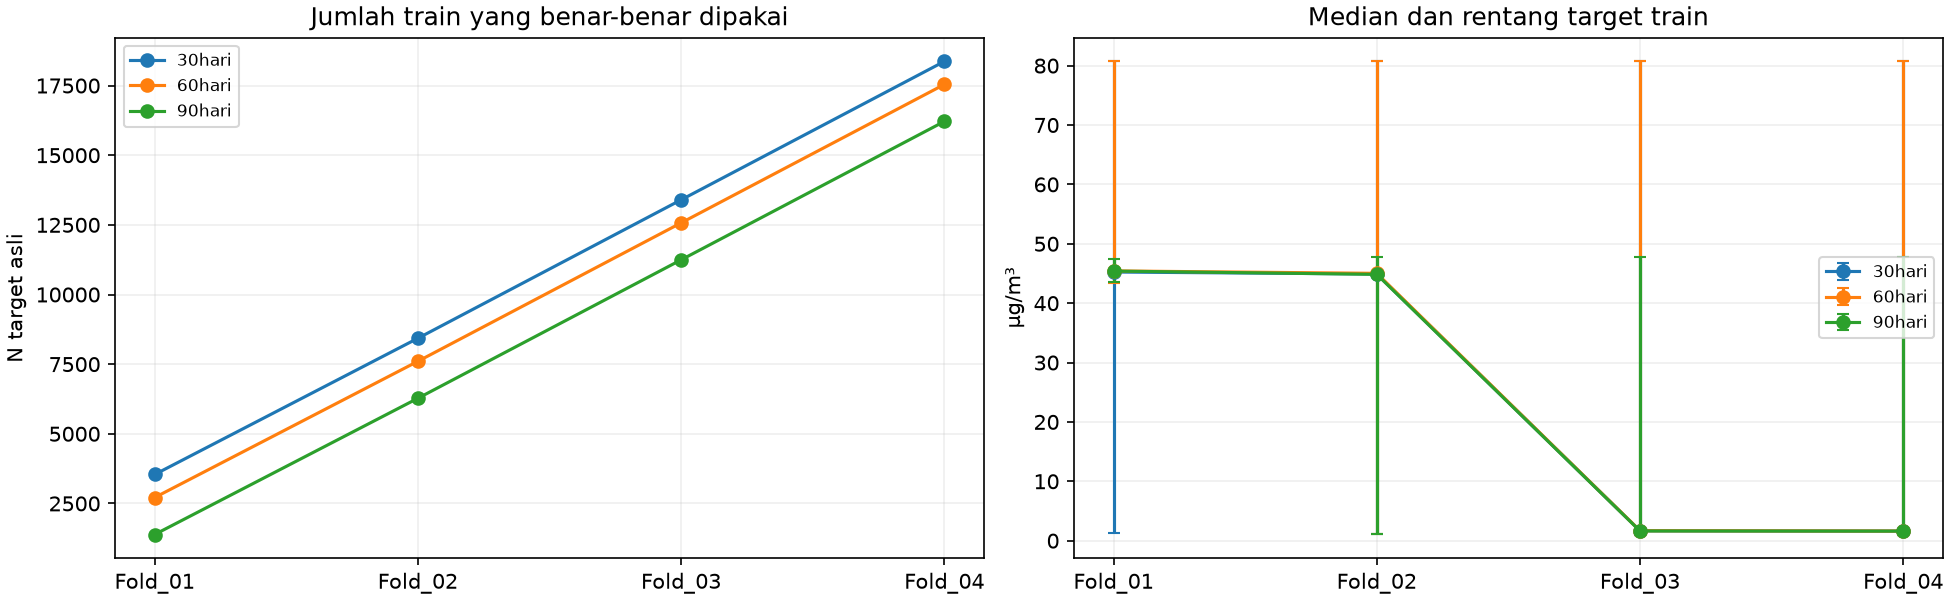

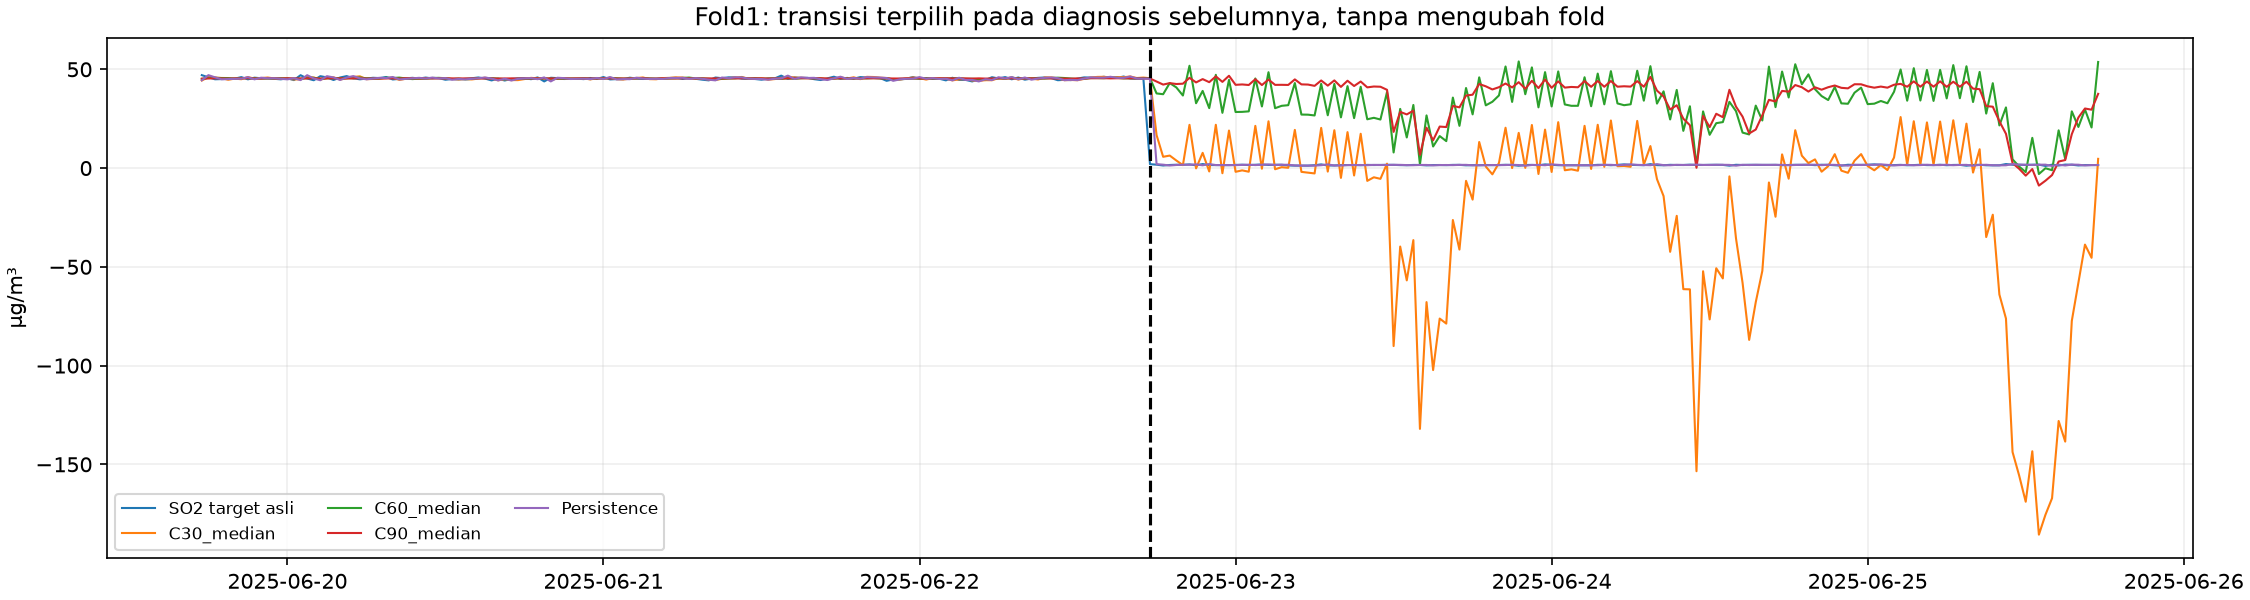

In [3]:
s.fit_and_summarize()
display(pd.DataFrame(s.metrics))
display(pd.DataFrame(s.pooled))
display(pd.DataFrame(s.variation))
display(pd.DataFrame(s.deltas))
display(pd.DataFrame(s.integrity))
for name in ['skor_antar_fold.png','komposisi_train.png','transisi_fold1.png']:
    display(Image(filename=str(ROOT/'outputs/figures/sensitivitas_kalibrasi'/name)))


In [4]:
s.export_excel()
display(Markdown((ROOT/'outputs/ringkasan_sensitivitas_kalibrasi.md').read_text(encoding='utf-8')))


{"kind":"table","sheet":"Ringkasan","address":"A1:F4","rows":4,"cols":6,"values":[["Fold","Konfigurasi","Domain","N","Denominator target asli","Cakupan persen"],["Gabungan_OOF","C30_median","mandiri",19797,19797,100],["Gabungan_OOF","C30_median","bersama",19797,19797,100],["Gabungan_OOF","C60_median","mandiri",19797,19797,100]]}
Inspect result written to file: C:\Users\INTAN\airpollutan_SO2\outputs\hasil_sensitivitas_kalibrasi.xlsx.inspect.ndjson
Ekspor selesai: 23 sheet.



# Sensitivitas periode kalibrasi — median dan Ridge Way Urang

**Satu metode imputasi dan satu model Ridge.** Tidak melatih deep learning, tidak mengubah empat fold kalender, tidak memuat atau mengevaluasi test akhir. Development set train+validasi lama telah dipakai eksperimen sebelumnya, sehingga hasil merupakan validasi pengembangan.

## Fungsi kalibrasi sebelum eksperimen

Implementasi `Forecast.impute_history` sebelumnya memakai90 hari pertama sebagai **warmup statistik**, bukan kalibrasi alat. Data awal itu tetap mentah dan menyediakan prefix median. Imputasi histori baru dimulai sesudah warmup; median train diperbarui setiap30 hari menggunakan raw prefix yang berakhir sebelum awal query. Sampel Ridge dimulai setelah tambahan48 slot untuk lag terpanjang. Saat evaluasi, median dibekukan dari seluruh train fold. Scaler Ridge dan koefisien diestimasi hanya dari train yang layak.

Pilihan90 hari adalah keputusan rancangan terdahulu, bukan hasil dokumentasi sensor atau bukti kebutuhan90 hari. Mempersingkatnya mengubah tanggal pertama sampel model, komposisi target serta representasi histori awal train. Penjelasan ini disampaikan sebelum model sensitivitas dijalankan.

## Rancangan terkunci

Kalibrasi30/60/90 hari, buffer48 slot, pembaruan prefix 30 hari; horizon30menit; SO₂lag0/1/2/6/12/24/48, sepuluh kovariatlag1 tanpa CurahHujan, serta17 indikator missing asli. Scaler StandardScaler pada seluruh 34 fitur, Ridge alpha 1, intercept aktif, solver SVD, CPU 1 thread; target tidak diskalakan. Tidak ada tuning, clipping atau fallback. Konfigurasi dikunci sebelum12fit, SHA256: 594d344745fda9723d5b00b106a83977fedd6aa11a5636155ce1dc51025abfa8.

| Fold | Train mulai | Train akhir | Validasi mulai | Validasi akhir |
|---|---|---|---|---|
| Fold_01 | 2025-01-01 00:00:00 | 2025-04-30 23:30:00 | 2025-05-01 00:00:00 | 2025-08-12 13:30:00 |
| Fold_02 | 2025-01-01 00:00:00 | 2025-08-12 13:30:00 | 2025-08-12 14:00:00 | 2025-11-24 03:00:00 |
| Fold_03 | 2025-01-01 00:00:00 | 2025-11-24 03:00:00 | 2025-11-24 03:30:00 | 2026-03-07 16:30:00 |
| Fold_04 | 2025-01-01 00:00:00 | 2026-03-07 16:30:00 | 2026-03-07 17:00:00 | 2026-06-19 06:00:00 |

Test akhir tetap mulai2026-06-19 06:30. Pembacaan grid dibatasi25.645 slot development. Data asli, nol, lonjakan, nilai konstan dan penanda kualitas dipertahankan; off-grid tidak dibulatkan. Ketersediaan SO₂di origin dan kovariatlag1 mengikuti asumsi tahap 6; latensi aktual dan zona waktu tidak ditebak.

Median tiapkolom berasal dari raw prefix eksklusif awal query; bila belum ada nilai, median tetapNaN dan kegagalannya dicatat. Fitur train historis tidak diisi ulang dengan informasi dari akhir train. StandardScaler untuk regresi memakai seluruh train eligible yang sudah tersedia sebelum origin evaluasi pertama; tidak menggunakan data evaluasi atau parameter seluruh development.

**Train mandiri per durasi:** uji ini tidak memaksakan irisan train30/60/90 hari, karena perubahan sampel adalah bagian tujuan. Tidak pula memakai irisan ffill/KNN tahap 6. Karena itu C90 baru dapat berbeda dari median tahap 6 meskipun matriks fitur90 hari identik. Audit perbedaannya:

| Fold | Train P0 tahap 6 irisan3 | C90 median mandiri | Tambahan karena tidak memakai irisan P1 KNN | Minimum | Median | Maksimum |
|---|---|---|---|---|---|---|
| Fold_01 | 1379 | 1385 | 6 | 44.55 | 45.20 | 46.28 |
| Fold_02 | 6190 | 6275 | 85 | 1.16 | 44.87 | 46.68 |
| Fold_03 | 11154 | 11244 | 90 | 1.16 | 44.68 | 46.68 |
| Fold_04 | 16086 | 16213 | 127 | 1.16 | 1.73 | 46.68 |

Tanggal evaluasi tetap, tetapi tahap 6 membatasi skor utamanya pada irisan median/ffill/KNN. Uji median saja ini mengevaluasi semua target asli pada tanggal yang sama dan kemudian mengambil irisan30/60/90+persistence. Karena cakupan dan cohort train berbeda, skor C90 baru tidak boleh dibandingkan langsung dengan skor utama lama sebagai efek perubahan kalibrasi. Semua perbandingan utama di sini berada pada timestamp identik antarketiga durasi.

## Sampel train dan alasan tersisih

| Fold | Kalibrasi hari | Slot origin train | Warmup dikeluarkan | Buffer lag48 | Purge batas | Kandidat setelah warmup buffer purge | Target kosong kandidat | Fitur nonfinite kandidat target teramati | Train dipakai | Jumlah tersisih |
|---|---|---|---|---|---|---|---|---|---|---|
| Fold_01 | 30 | 5760 | 1440 | 48 | 1 | 4271 | 732 | 0 | 3539 | 2221 |
| Fold_01 | 60 | 5760 | 2880 | 48 | 1 | 2831 | 119 | 0 | 2712 | 3048 |
| Fold_01 | 90 | 5760 | 4320 | 48 | 1 | 1391 | 6 | 0 | 1385 | 4375 |
| Fold_02 | 30 | 10732 | 1440 | 48 | 1 | 9243 | 814 | 0 | 8429 | 2303 |
| Fold_02 | 60 | 10732 | 2880 | 48 | 1 | 7803 | 201 | 0 | 7602 | 3130 |
| Fold_02 | 90 | 10732 | 4320 | 48 | 1 | 6363 | 88 | 0 | 6275 | 4457 |
| Fold_03 | 30 | 15703 | 1440 | 48 | 1 | 14214 | 816 | 0 | 13398 | 2305 |
| Fold_03 | 60 | 15703 | 2880 | 48 | 1 | 12774 | 203 | 0 | 12571 | 3132 |
| Fold_03 | 90 | 15703 | 4320 | 48 | 1 | 11334 | 90 | 0 | 11244 | 4459 |
| Fold_04 | 30 | 20674 | 1440 | 48 | 1 | 19185 | 818 | 0 | 18367 | 2307 |
| Fold_04 | 60 | 20674 | 2880 | 48 | 1 | 17745 | 205 | 0 | 17540 | 3134 |
| Fold_04 | 90 | 20674 | 4320 | 48 | 1 | 16305 | 92 | 0 | 16213 | 4461 |

Ledger CSV percase menyimpan **semua origin**, bukan menghapus baris sumber. Alasanutama eksklusif berurutan: warmup, buffer, purge, target kosong, fitur nonfinite, digunakan; jumlahnya tepat totalorigin train. Boolean alasan dan hitungan tumpang-tindih disimpan terpisah dan tidak dijumlahkan sebagai kategori independen. Hanya34 fitur dan target asli yang diuji, tidak ada dropna pada kolom lain. Nilai target yang melintasi batas tidak masuk statistik train.

| Fold | Kalibrasi hari | Target awal | Target akhir | N | Minimum | P1 | P25 | Median | P75 | P99 | Maksimum | Mean | SD |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| Fold_01 | 30 | 2025-02-13 19:00:00 | 2025-04-30 23:30:00 | 3539 | 1.24 | 1.33 | 44.42 | 45.24 | 45.82 | 77.35 | 80.71 | 38.47 | 19.89 |
| Fold_01 | 60 | 2025-03-03 00:30:00 | 2025-04-30 23:30:00 | 2712 | 43.31 | 43.98 | 45.00 | 45.43 | 45.89 | 76.90 | 80.71 | 46.51 | 5.74 |
| Fold_01 | 90 | 2025-04-02 00:30:00 | 2025-04-30 23:30:00 | 1385 | 43.53 | 44.03 | 45.00 | 45.40 | 45.82 | 46.93 | 47.43 | 45.40 | 0.62 |
| Fold_02 | 30 | 2025-02-13 19:00:00 | 2025-08-12 13:30:00 | 8429 | 1.07 | 1.30 | 1.58 | 44.91 | 45.61 | 75.93 | 80.71 | 29.83 | 22.34 |
| Fold_02 | 60 | 2025-03-03 00:30:00 | 2025-08-12 13:30:00 | 7602 | 1.07 | 1.30 | 1.65 | 45.02 | 45.64 | 74.48 | 80.71 | 31.76 | 21.02 |
| Fold_02 | 90 | 2025-04-02 00:30:00 | 2025-08-12 13:30:00 | 6275 | 1.07 | 1.29 | 1.60 | 44.85 | 45.54 | 46.79 | 47.81 | 28.40 | 21.37 |
| Fold_03 | 30 | 2025-02-13 19:00:00 | 2025-11-24 03:00:00 | 13398 | 1.04 | 1.24 | 1.52 | 1.66 | 45.20 | 75.01 | 80.71 | 19.35 | 22.37 |
| Fold_03 | 60 | 2025-03-03 00:30:00 | 2025-11-24 03:00:00 | 12571 | 1.04 | 1.24 | 1.54 | 1.68 | 45.23 | 47.09 | 80.71 | 19.82 | 22.03 |
| Fold_03 | 90 | 2025-04-02 00:30:00 | 2025-11-24 03:00:00 | 11244 | 1.04 | 1.22 | 1.53 | 1.64 | 45.02 | 46.62 | 47.81 | 16.54 | 20.80 |
| Fold_04 | 30 | 2025-02-13 19:00:00 | 2026-03-07 16:30:00 | 18367 | 1.04 | 1.23 | 1.51 | 1.61 | 44.71 | 73.77 | 80.71 | 14.54 | 20.67 |
| Fold_04 | 60 | 2025-03-03 00:30:00 | 2026-03-07 16:30:00 | 17540 | 1.04 | 1.22 | 1.52 | 1.62 | 44.77 | 46.83 | 80.71 | 14.65 | 20.38 |
| Fold_04 | 90 | 2025-04-02 00:30:00 | 2026-03-07 16:30:00 | 16213 | 1.04 | 1.22 | 1.51 | 1.61 | 1.87 | 46.49 | 47.81 | 11.95 | 18.64 |

Distribusi bulanan dan distribusi target menurut alasan tersisih ada di workbook. Target selalu nilai asli numerik yang teramati, bukan hasil imputasi atau pernyataan validitas sensor. Angka2,14µg/m³ hanya pelacak hasil lama, bukan ambang kualitas/bahaya.

Tambahan sampel dibanding train90 hari:

| Fold | Kalibrasi hari | N | Minimum | Median | Maksimum | SO2 lebih2.14 |
|---|---|---|---|---|---|---|
| Fold_01 | 30 | 2154 | 1.24 | 45.06 | 80.71 | 1447 |
| Fold_01 | 60 | 1327 | 43.31 | 45.47 | 80.71 | 1327 |
| Fold_01 | 90 | 0 | — | — | — | 0 |
| Fold_02 | 30 | 2154 | 1.24 | 45.06 | 80.71 | 1447 |
| Fold_02 | 60 | 1327 | 43.31 | 45.47 | 80.71 | 1327 |
| Fold_02 | 90 | 0 | — | — | — | 0 |
| Fold_03 | 30 | 2154 | 1.24 | 45.06 | 80.71 | 1447 |
| Fold_03 | 60 | 1327 | 43.31 | 45.47 | 80.71 | 1327 |
| Fold_03 | 90 | 0 | — | — | — | 0 |
| Fold_04 | 30 | 2154 | 1.24 | 45.06 | 80.71 | 1447 |
| Fold_04 | 60 | 1327 | 43.31 | 45.47 | 80.71 | 1327 |
| Fold_04 | 90 | 0 | — | — | — | 0 |

## Performa pada timestamp identik

| Fold | Konfigurasi | N | Denominator target asli | Cakupan persen | MAE | RMSE | Bias | Prediksi negatif |
|---|---|---|---|---|---|---|---|---|
| Fold_01 | C30_median | 4890 | 4890 | 100.000 | 17.245739 | 40.229392 | -11.924223 | 1317 |
| Fold_01 | C60_median | 4890 | 4890 | 100.000 | 15.796595 | 23.826218 | 15.247600 | 91 |
| Fold_01 | C90_median | 4890 | 4890 | 100.000 | 16.655304 | 24.730388 | 16.110781 | 103 |
| Fold_01 | Persistence | 4890 | 4890 | 100.000 | 0.430562 | 0.885256 | 0.009049 | 0 |
| Fold_02 | C30_median | 4969 | 4969 | 100.000 | 0.216147 | 0.608248 | -0.110496 | 0 |
| Fold_02 | C60_median | 4969 | 4969 | 100.000 | 0.300260 | 0.617374 | -0.173761 | 1 |
| Fold_02 | C90_median | 4969 | 4969 | 100.000 | 0.183688 | 0.382087 | -0.077911 | 1 |
| Fold_02 | Persistence | 4969 | 4969 | 100.000 | 0.142954 | 0.183682 | -0.000020 | 0 |
| Fold_03 | C30_median | 4969 | 4969 | 100.000 | 0.123171 | 0.178886 | -0.023703 | 2 |
| Fold_03 | C60_median | 4969 | 4969 | 100.000 | 0.128391 | 0.182587 | -0.035229 | 4 |
| Fold_03 | C90_median | 4969 | 4969 | 100.000 | 0.124338 | 0.273503 | -0.026474 | 6 |
| Fold_03 | Persistence | 4969 | 4969 | 100.000 | 0.139453 | 0.178418 | 0.000016 | 0 |
| Fold_04 | C30_median | 4969 | 4969 | 100.000 | 0.103623 | 0.154645 | -0.012214 | 2 |
| Fold_04 | C60_median | 4969 | 4969 | 100.000 | 0.108887 | 0.160042 | -0.019969 | 2 |
| Fold_04 | C90_median | 4969 | 4969 | 100.000 | 0.106864 | 0.237953 | -0.022582 | 6 |
| Fold_04 | Persistence | 4969 | 4969 | 100.000 | 0.115935 | 0.149092 | 0.000024 | 0 |

e=prediksi−pengamatan asli. MAE=Σ|e|/N, RMSE=√(Σe²/N), bias=Σe/N dalamµg/m³. Cakupan(%)=Nprediksi finite / seluruh target asli teramati jendela×100. Domainbersama memakai irisan3durasi+persistence dengan denominator sama. Cakupan mandiri juga disimpan terhadap semua target asli. Targetkosong tidak pernah diisi untuk penilaian.

| Fold | Konfigurasi | N | Cakupan persen | MAE | RMSE | Bias |
|---|---|---|---|---|---|---|
| Fold_01 | C30_median | 4890 | 100.000 | 17.245739 | 40.229392 | -11.924223 |
| Fold_01 | C60_median | 4890 | 100.000 | 15.796595 | 23.826218 | 15.247600 |
| Fold_01 | C90_median | 4890 | 100.000 | 16.655304 | 24.730388 | 16.110781 |
| Fold_01 | Persistence | 4890 | 100.000 | 0.430562 | 0.885256 | 0.009049 |
| Fold_02 | C30_median | 4969 | 100.000 | 0.216147 | 0.608248 | -0.110496 |
| Fold_02 | C60_median | 4969 | 100.000 | 0.300260 | 0.617374 | -0.173761 |
| Fold_02 | C90_median | 4969 | 100.000 | 0.183688 | 0.382087 | -0.077911 |
| Fold_02 | Persistence | 4969 | 100.000 | 0.142954 | 0.183682 | -0.000020 |
| Fold_03 | C30_median | 4969 | 100.000 | 0.123171 | 0.178886 | -0.023703 |
| Fold_03 | C60_median | 4969 | 100.000 | 0.128391 | 0.182587 | -0.035229 |
| Fold_03 | C90_median | 4969 | 100.000 | 0.124338 | 0.273503 | -0.026474 |
| Fold_03 | Persistence | 4969 | 100.000 | 0.139453 | 0.178418 | 0.000016 |
| Fold_04 | C30_median | 4969 | 100.000 | 0.103623 | 0.154645 | -0.012214 |
| Fold_04 | C60_median | 4969 | 100.000 | 0.108887 | 0.160042 | -0.019969 |
| Fold_04 | C90_median | 4969 | 100.000 | 0.106864 | 0.237953 | -0.022582 |
| Fold_04 | Persistence | 4969 | 100.000 | 0.115935 | 0.149092 | 0.000024 |

Persistence memakai pengamatan SO₂asli terakhir yang tersedia pada atau sebelum origin, bukan hasil imputasi; donor boleh lebih lama tanpa batasumur seperti tahap 6. Usia donor dicatat per prediksi. Semua perbandingan bersama memiliki digesttimestamp identik.

| Fold | Konfigurasi | Delta MAE vs persistence | Delta RMSE vs persistence | Delta Bias vs persistence |
|---|---|---|---|---|
| Fold_01 | C30_median | 16.815177 | 39.344136 | -11.933272 |
| Fold_01 | C60_median | 15.366033 | 22.940963 | 15.238551 |
| Fold_01 | C90_median | 16.224742 | 23.845132 | 16.101732 |
| Fold_02 | C30_median | 0.073193 | 0.424566 | -0.110476 |
| Fold_02 | C60_median | 0.157306 | 0.433692 | -0.173740 |
| Fold_02 | C90_median | 0.040734 | 0.198406 | -0.077891 |
| Fold_03 | C30_median | -0.016282 | 0.000468 | -0.023719 |
| Fold_03 | C60_median | -0.011062 | 0.004170 | -0.035245 |
| Fold_03 | C90_median | -0.015115 | 0.095085 | -0.026490 |
| Fold_04 | C30_median | -0.012312 | 0.005553 | -0.012238 |
| Fold_04 | C60_median | -0.007048 | 0.010951 | -0.019993 |
| Fold_04 | C90_median | -0.009071 | 0.088861 | -0.022606 |

Delta negatif berarti lebih rendah daripada persistence, tetapi bias harus dibaca kedekatannya terhadap nol.

## Gabungan dan kestabilan

| Konfigurasi | N | Cakupan persen | MAE | RMSE | Bias |
|---|---|---|---|---|---|
| C30_median | 19797 | 100.000 | 4.370998 | 19.996605 | -2.982118 |
| C60_median | 19797 | 100.000 | 4.036792 | 11.846249 | 3.708798 |
| C90_median | 19797 | 100.000 | 4.218115 | 12.293788 | 3.947609 |
| Persistence | 19797 | 100.000 | 0.206335 | 0.464340 | 0.002240 |

Gabungan dihitung ulang dari error semua prediksi OOF unik, bukan rata-rataRMSE fold. Mean danSD sampel antar4fold (ddof1) disajikan terpisah:

| Konfigurasi | MAE mean fold | MAE SD fold | RMSE mean fold | RMSE SD fold | Bias mean fold |
|---|---|---|---|---|---|
| C30_median | 4.422170 | 8.549187 | 10.292793 | 19.958820 | -3.017659 |
| C60_median | 4.083533 | 7.809181 | 6.196556 | 11.754993 | 3.754660 |
| C90_median | 4.267549 | 8.258569 | 6.405983 | 12.216424 | 3.995954 |
| Persistence | 0.207226 | 0.149373 | 0.349112 | 0.357753 | 0.002267 |

| Fold | Konfigurasi | Rank MAE | Rank RMSE |
|---|---|---|---|
| Fold_01 | C30_median | 3.000000 | 3.000000 |
| Fold_01 | C60_median | 1.000000 | 1.000000 |
| Fold_01 | C90_median | 2.000000 | 2.000000 |
| Fold_02 | C30_median | 2.000000 | 2.000000 |
| Fold_02 | C60_median | 3.000000 | 3.000000 |
| Fold_02 | C90_median | 1.000000 | 1.000000 |
| Fold_03 | C30_median | 1.000000 | 1.000000 |
| Fold_03 | C60_median | 3.000000 | 2.000000 |
| Fold_03 | C90_median | 2.000000 | 3.000000 |
| Fold_04 | C30_median | 1.000000 | 1.000000 |
| Fold_04 | C60_median | 3.000000 | 2.000000 |
| Fold_04 | C90_median | 2.000000 | 3.000000 |

Tidak mengklaim signifikansi statistik dari selisih rata-rata. Fold saling terkait karena train expanding dan development telah dipakai sebelumnya. Skor perbulan tersimpan untuk memeriksa perubahan performa di dalam jendela.

## Apa yang sebenarnya berubah

| Fold | Kalibrasi hari | Fitur evaluasi belum scaling identik antar kalibrasi | Selisih maksimum finite |
|---|---|---|---|
| Fold_01 | 30 | True | 0.00 |
| Fold_01 | 60 | True | 0.00 |
| Fold_01 | 90 | True | 0.00 |
| Fold_02 | 30 | True | 0.00 |
| Fold_02 | 60 | True | 0.00 |
| Fold_02 | 90 | True | 0.00 |
| Fold_03 | 30 | True | 0.00 |
| Fold_03 | 60 | True | 0.00 |
| Fold_03 | 90 | True | 0.00 |
| Fold_04 | 30 | True | 0.00 |
| Fold_04 | 60 | True | 0.00 |
| Fold_04 | 90 | True | 0.00 |

Jika seluruh fitur evaluasi sebelum scaling identik, hasil itu menunjukkan bahwa jadwal prefix30 hari yang sama sesudah hari90 dan evaluasi mulai sesudah hari120 menghasilkan masukan yang sama pada saat evaluasi. Namun scaler regresi, koefisien, distribusi train dan histori imputasi sebelum hari90 dapat berbeda. Hasil bukan efek median saja, bukan kalibrasi alat, dan bukan bukti sebab fisik perubahan konsentrasi.

![Komposisi train](figures/sensitivitas_kalibrasi/komposisi_train.png)

![Skor antar-fold](figures/sensitivitas_kalibrasi/skor_antar_fold.png)

![Transisi fold1](figures/sensitivitas_kalibrasi/transisi_fold1.png)

## Penilaian terbatas

- C30_median: MAE danRMSE sekaligus lebih rendah dari persistence pada 0/4fold; baca bersama bias, cakupan dan keterwakilan distribusi train.
- C60_median: MAE danRMSE sekaligus lebih rendah dari persistence pada 0/4fold; baca bersama bias, cakupan dan keterwakilan distribusi train.
- C90_median: MAE danRMSE sekaligus lebih rendah dari persistence pada 0/4fold; baca bersama bias, cakupan dan keterwakilan distribusi train.

Temuan aktual: C60 memiliki MAE/RMSE gabungan terendah di antara ketiga durasi, namun keuntungan itu terutama dari fold 1. Peringkat per periode berubah: C60 terendah pada fold 1, C90 pada fold 2, C30 pada fold 3 dan 4. Tidak ada konfigurasi yang mengungguli persistence pada MAE dan RMSE sekaligus di satu fold pun. Pada fold 3/4, MAE Ridge bisa lebih rendah tetapi RMSE masih lebih tinggi daripada persistence.

Pada fold 1, warmup 30 hari menambah train menjadi 3.539 target (rentang 1,24–80,71 µg/m³), termasuk 707 target ≤2,14 sebagai pelacak rezim rendah; C60 menggunakan 2.712 target (43,31–80,71), C90 menggunakan 1.385 target (43,53–47,43). Meski train C30 lebih beragam, MAE 17,245739 dan RMSE 40,229392 masih jauh di atas persistence (0,430562 dan 0,885256). Jadi cakupan rentang train lebih luas tidak otomatis memperbaiki generalisasi. Konsentrasi itu tidak dihapus atau dinyatakan salah.

Semua durasi memiliki 100% cakupan terhadap 19.797 target asli teramati, dan fitur evaluasi sebelum scaling identik (selisih maksimum 0). Oleh karena itu perbedaan skor antar-durasi di sini bukan akibat titik evaluasi atau nilai median evaluasi yang berbeda. Perubahan cohort, histori imputasi awal train dan estimasi scaler/Ridge tetap terlibat. C30 menghasilkan 1.321 prediksi negatif gabungan, C60 sebanyak 98 dan C90 sebanyak 116, tanpa clipping; pola keluaran ini perlu ditelusuri sebelum memilih warmup.

Tidak memilih konfigurasi hanya dari rerata error terendah. Warmup pendek dapat membuka periode train lebih beragam sekaligus mengubah representasi missing; warmup panjang dapat menghasilkan cohort sempit dan menyingkirkan rezim yang penting. Semua hasil perlu dibaca per periode dan metrik dengan cakupan yang sepadan. Tidak membuka test untuk memilih durasi dan tidak melatih arsitektur lain.

## Reproduksibilitas dan integritas

| Fold | Kalibrasi hari | Preprocessing detik | Scaler fit detik | Ridge fit detik | Predict detik |
|---|---|---|---|---|---|
| Fold_01 | 30 | 0.039128 | 0.195911 | 0.025340 | 0.006373 |
| Fold_01 | 60 | 0.020545 | 0.007583 | 0.014502 | 0.005918 |
| Fold_01 | 90 | 0.014454 | 0.005515 | 0.005229 | 0.004069 |
| Fold_02 | 30 | 0.058442 | 0.015810 | 0.034320 | 0.006258 |
| Fold_02 | 60 | 0.053289 | 0.019278 | 0.020454 | 0.004824 |
| Fold_02 | 90 | 0.055831 | 0.007486 | 0.017517 | 0.002998 |
| Fold_03 | 30 | 0.088607 | 0.018086 | 0.037184 | 0.003952 |
| Fold_03 | 60 | 0.081177 | 0.021858 | 0.049844 | 0.006365 |
| Fold_03 | 90 | 0.036597 | 0.024930 | 0.046204 | 0.006221 |
| Fold_04 | 30 | 0.048458 | 0.032500 | 0.085275 | 0.007133 |
| Fold_04 | 60 | 0.134949 | 0.039908 | 0.072330 | 0.006013 |
| Fold_04 | 90 | 0.081550 | 0.024395 | 0.060722 | 0.005512 |

367 sumber/artefak lama identik SHA256 terhadap baseline saat uji ini dimulai, termasuk seluruh hasil LSTM dan checkpointnya. Perbedaan notebook 02 yang telah dicatat pada tahap 7 menjadi kondisi awal dan tidak diperbaiki. Tidak ada file lama ditimpa. Hashing byte untuk integritas tidak membaca nilai test secara semantik.

Notebook: `notebooks/08_sensitivitas_kalibrasi_ridge.ipynb`. Konfigurasi, gate pra-fit, input/fitur, timestamp train, ledger alasan, parameter Ridge/scaler dan prediksi tersimpan di `outputs/sensitivitas_kalibrasi/`. Seluruh tabel pada `hasil_sensitivitas_kalibrasi.xlsx`; prediksi semua konfigurasi tersedia sebagai CSV; grafik di `figures/sensitivitas_kalibrasi/`.
